# 04. Проверка итоговых данных

Не EDA, а приёмка: всё ли собрано правильно и несут ли признаки сигнал. Каждая проверка печатает
**OK** или **ВНИМАНИЕ** с пояснением.

1. Целостность: экспорт для лабы совпадает с панелью, порядок станций, пропуски, границы выборок.
2. Флаг закрытий: не принимает ли он погоду за закрытие (буран, снегопады).
3. Качество рядов по станциям: нули, разрывы уровня, «подозрительные» станции.
4. Перевод часов: сдвоенный час.
5. Полезность событий: насколько выше спрос в часы матчей.
6. Полезность графа: похожи ли колебания спроса у связанных станций.

In [1]:
import sys, json
sys.path.append("../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from config import PROCESSED, RAW, SPLITS, TRAIN_END

COL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
INK2, MUTED, GRID = "#52514e", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.figsize": (11, 4), "figure.dpi": 110, "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "xtick.color": MUTED, "ytick.color": MUTED, "lines.linewidth": 2, "legend.frameon": False,
})
pd.set_option("display.max_rows", 60, "display.max_colwidth", 60)

def check(ok, msg):
    print(("OK          " if ok else "ВНИМАНИЕ    ") + msg)

LAB, GRAPH = PROCESSED / "lab", PROCESSED / "graph"
panel = pd.read_parquet(PROCESSED / "panel.parquet")
panel["station_complex_id"] = panel["station_complex_id"].astype(str)
st = pd.read_parquet(PROCESSED / "station_static.parquet")
name = st.set_index("station_complex_id")["station_complex"]
Y = pd.read_parquet(LAB / "ridership_wide.parquet")
C = pd.read_parquet(LAB / "closed_wide.parquet")
X = pd.read_parquet(LAB / "covariates_time.parquet")
nodes = pd.read_csv(GRAPH / "nodes.csv", dtype={"station_complex_id": str})
meta = json.loads((LAB / "split.json").read_text(encoding="utf-8"))
print(f"panel {panel.shape}, Y {Y.shape}, C {C.shape}, X {X.shape}, nodes {len(nodes)}")

panel (13868192, 5), Y (32708, 424), C (32708, 424), X (32708, 32), nodes 424


## 1. Целостность

In [2]:
check(Y.values.sum() == panel["ridership"].sum(), f"сумма входов в экспорте = в панели ({Y.values.sum():,})")
check(list(Y.columns) == nodes["station_complex_id"].tolist(), "столбцы ridership_wide = порядок узлов графа")
check(list(C.columns) == list(Y.columns) and C.index.equals(Y.index), "маска закрытий той же формы")
check(X.index.equals(Y.index), "ковариаты на той же сетке часов")
check(Y.index.is_monotonic_increasing and Y.index.is_unique, "часы упорядочены и без повторов")
gaps = Y.index.to_series().diff().dt.total_seconds().div(3600).value_counts()
check(set(gaps.index.dropna()) <= {1.0, 2.0} and gaps.get(2.0, 0) <= 4,
      f"шаг по времени: {dict(gaps)} (шаг 2 ч — только весенний перевод часов)")
nan_cols = X.columns[X.isna().any()].tolist()
check(not nan_cols, f"пропуски в ковариатах: {nan_cols or 'нет'}")
check(Y.isna().sum().sum() == 0 and (Y.values >= 0).all(), "в целевом ряду нет пропусков и отрицательных")
for k, (a, b) in SPLITS.items():
    n = ((Y.index >= a) & (Y.index <= b)).sum()
    print(f"            {k}: {a:%d.%m.%Y} – {b:%d.%m.%Y}, часов {n:,}")
check(meta["train"][1].startswith(str(TRAIN_END.date())), "split.json совпадает с config.py")
const = [c for c in X.columns if X.loc[X.index <= TRAIN_END, c].nunique() <= 1]
check(not const, f"ковариаты, постоянные на train (модель их не выучит): {const or 'нет'}")

OK          сумма входов в экспорте = в панели (4,626,526,673)
OK          столбцы ridership_wide = порядок узлов графа
OK          маска закрытий той же формы
OK          ковариаты на той же сетке часов
OK          часы упорядочены и без повторов
OK          шаг по времени: {1.0: np.int64(32703), 2.0: np.int64(4)} (шаг 2 ч — только весенний перевод часов)
OK          пропуски в ковариатах: нет
OK          в целевом ряду нет пропусков и отрицательных
            train: 01.01.2023 – 31.03.2026, часов 28,460
            val: 01.04.2026 – 30.06.2026, часов 2,184
            test: 01.07.2026 – 24.09.2026, часов 2,064
OK          split.json совпадает с config.py
OK          ковариаты, постоянные на train (модель их не выучит): нет


## 2. Флаг закрытий и погода

Правило «поток < 10% обычного» может принять за закрытие **погодный провал** (буран). Тогда сильнейшие
погодные дни выпадут из обучения и метрик — а это ровно то, что модель должна уметь прогнозировать.
Сравниваем число «закрытых» станций в худшие погодные дни с обычными днями того же дня недели.

In [3]:
closed_day = C.resample("D").max().sum(axis=1)          # станций, закрытых в этот день
dow_med = closed_day.groupby(closed_day.index.dayofweek).median()
days = {"буран 23.02.2026": "2026-02-23", "снегопад 25.01.2026": "2026-01-25",
        "снегопад 26.01.2026": "2026-01-26", "снег 13.02.2024": "2024-02-13", "наводнение 29.09.2023": "2023-09-29",
        "Рождество 25.12.2025": "2025-12-25"}
rows = []
for lab, d in days.items():
    d = pd.Timestamp(d)
    rows.append({"день": lab, "закрытых станций": int(closed_day.get(d, np.nan)),
                 "обычно в этот день недели": int(dow_med[d.dayofweek])})
t = pd.DataFrame(rows)
display(t)
bad = t[t["закрытых станций"] > t["обычно в этот день недели"] + 10]
check(bad.empty, "погодные дни не помечаются массово как закрытия" if bad.empty else
      f"в {len(bad)} днях флаг закрытий сработал на погоду: {bad['день'].tolist()} — см. вывод ниже")

,день,закрытых станций,обычно в этот день недели
0,буран 23.02.2026,6,0
1,снегопад 25.01.2026,1,20
2,снегопад 26.01.2026,0,0
3,снег 13.02.2024,0,0
4,наводнение 29.09.2023,0,0
5,Рождество 25.12.2025,1,0


OK          погодные дни не помечаются массово как закрытия


In [4]:
# Для таких дней: какие станции помечены и какой у них был поток
for lab, d in days.items():
    d = pd.Timestamp(d)
    extra = int(closed_day.get(d, 0) - dow_med[d.dayofweek])
    if extra > 10:
        ids = C.loc[d:d + pd.Timedelta(hours=23)].any()
        ids = ids[ids].index
        print(f"{lab}: помечено {len(ids)} станций, примеры: " + "; ".join(name.reindex(ids[:6]).fillna("?")))

## 3. Качество рядов по станциям

In [5]:
open_mask = ~C.values
daily = Y.resample("D").sum()
cd = C.resample("D").max()
yr = daily.where(~cd)                                   # закрытые дни убраны
q = pd.DataFrame({
    "станция": name.reindex(Y.columns).values,
    "входов в день (медиана)": yr.median().round().values,
    "закрытых дней": cd.sum().values,
    "часов-нулей при открытой станции, %": ((Y.values == 0) & open_mask).sum(0) / open_mask.sum(0) * 100,
    # разрыв уровня: медиана последних 6 мес. train к первым 6 мес.
    "уровень конец/начало": (yr.loc["2025-10-01":"2026-03-31"].median() / yr.loc["2023-01-01":"2023-06-30"].median()).values,
}, index=Y.columns)
q["часов-нулей при открытой станции, %"] = q["часов-нулей при открытой станции, %"].round(1)
q["уровень конец/начало"] = q["уровень конец/начало"].round(2)
print("Распределение «уровень конец/начало» (рост за 3 года, по станциям):")
print(q["уровень конец/начало"].describe().round(2).to_string())
odd = q[(q["уровень конец/начало"] > 1.6) | (q["уровень конец/начало"] < 0.7)]
check(len(odd) <= 10, f"станций с резким изменением уровня (>1.6× или <0.7×): {len(odd)}")
display(odd.sort_values("уровень конец/начало"))
zeros = q[q["часов-нулей при открытой станции, %"] > 20]
check(len(zeros) <= 10, f"станций, где >20% открытых часов без входов: {len(zeros)}")
display(zeros.sort_values("часов-нулей при открытой станции, %", ascending=False).head(15))

Распределение «уровень конец/начало» (рост за 3 года, по станциям):
count    424.00
mean       1.13
std        0.21
min        0.50
25%        1.04
50%        1.12
75%        1.18
max        4.36
OK          станций с резким изменением уровня (>1.6× или <0.7×): 7


,станция,входов в день (медиана),закрытых дней,"часов-нулей при открытой станции, %",уровень конец/начало
station_complex_id,,,,,
455,69 St (7),3350.0,24,0.3,0.50
457,52 St (7),3633.0,24,0.2,0.57
374,E 143 St-St Mary's St (6),947.0,10,4.5,1.66
133,Atlantic Av (L),1287.0,51,1.4,1.71
85,"75 St-Elderts Ln (J,Z)",1540.0,122,1.8,1.72
83,"Woodhaven Blvd (J,Z)",2172.0,122,1.0,1.90
138,Canarsie-Rockaway Pkwy (L),2208.0,33,0.2,4.36


OK          станций, где >20% открытых часов без входов: 0


,станция,входов в день (медиана),закрытых дней,"часов-нулей при открытой станции, %",уровень конец/начало
station_complex_id,,,,,


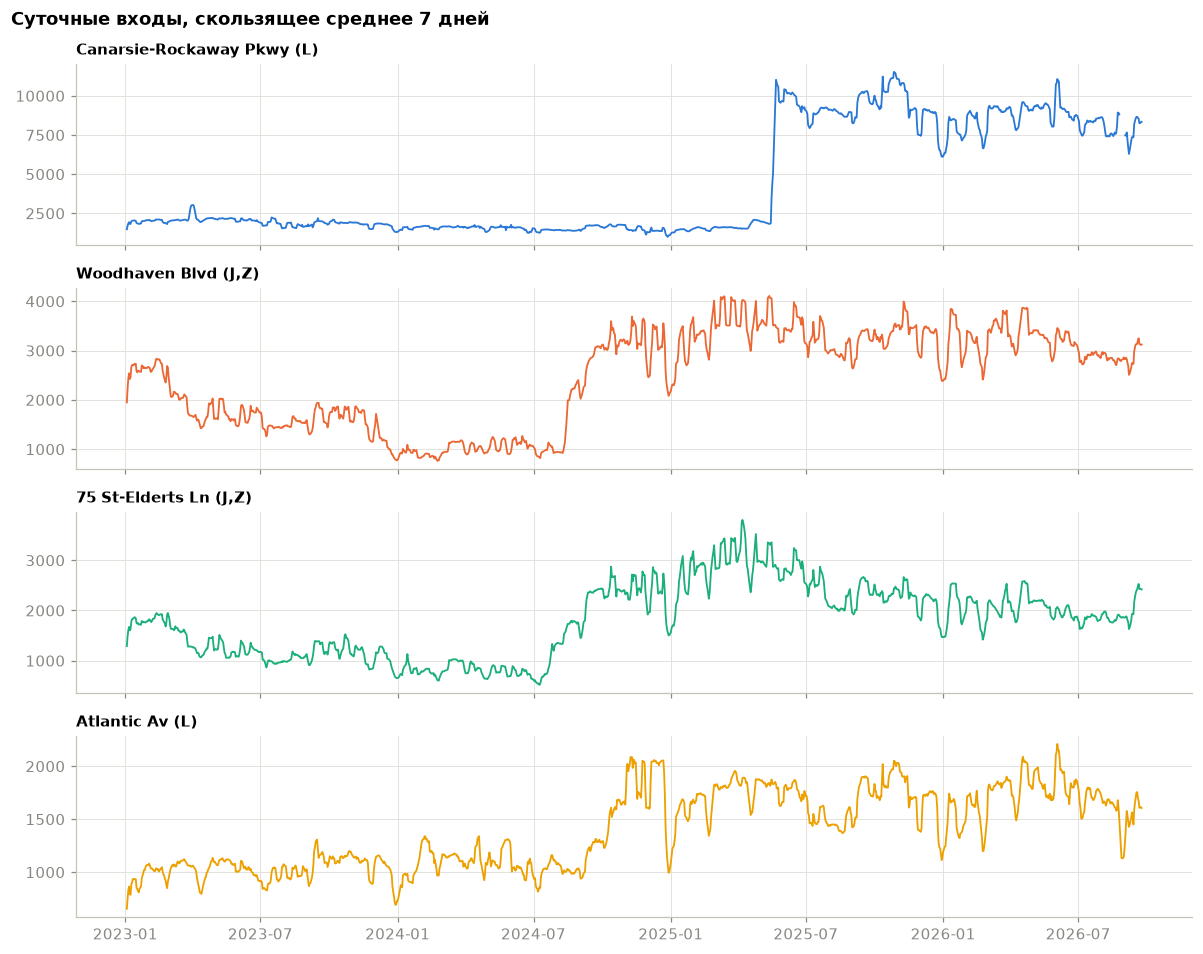

In [6]:
# Глазами: суточные входы нескольких станций с самым резким изменением уровня
show = odd.reindex(odd["уровень конец/начало"].sub(1).abs().sort_values(ascending=False).index).head(4).index
if len(show):
    fig, axes = plt.subplots(len(show), 1, figsize=(11, 2.2 * len(show)), sharex=True)
    for ax, sid, c in zip(np.atleast_1d(axes), show, COL):
        ax.plot(yr.index, yr[sid].rolling(7, min_periods=3).mean(), color=c, linewidth=1.2)
        ax.set_title(str(name.get(sid, sid)), fontsize=10)
    fig.suptitle("Суточные входы, скользящее среднее 7 дней", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(); plt.show()

## 4. Перевод часов

In [7]:
dst = X.index[X["is_dst_double_hour"] == 1]
for t0 in dst:
    tot = Y.sum(axis=1)
    prev = tot.get(t0 - pd.Timedelta(hours=1)); nxt = tot.get(t0 + pd.Timedelta(hours=1)); cur = tot[t0]
    print(f"{t0}: входов {cur:,.0f}; час до {prev:,.0f}, час после {nxt:,.0f} → отношение {cur / ((prev + nxt) / 2):.2f}")
print("Ожидание: около 2 (в 01:00 сложены два часа). Модели стоит дать флаг или поделить этот час пополам.")

2023-11-05 01:00:00: входов 31,225; час до 39,563, час после 7,188 → отношение 1.34
2024-11-03 01:00:00: входов 36,381; час до 44,800, час после 8,992 → отношение 1.35
2025-11-02 01:00:00: входов 47,432; час до 60,784, час после 11,743 → отношение 1.31
Ожидание: около 2 (в 01:00 сложены два часа). Модели стоит дать флаг или поделить этот час пополам.


## 5. Полезность событий

Средние входы на станциях у площадок в часы окна события против тех же часов дня недели без события.

In [8]:
ev_path = PROCESSED / "events_station_hour.parquet"
if ev_path.exists():
    ev = pd.read_parquet(ev_path)
    ev["station_complex_id"] = ev["station_complex_id"].astype(str)
    rows = []
    for sid in ev["station_complex_id"].unique():
        s = Y[sid].where(~C[sid]).to_frame("y")
        s["hour"], s["dow"] = s.index.hour, s.index.dayofweek
        e = ev[(ev["station_complex_id"] == sid) & (ev["ev_active"] > 0)].set_index("transit_timestamp")
        s["ev"] = s.index.isin(e.index)
        s["k"] = e["ev_hours_from_start"].reindex(s.index)
        base = s[~s["ev"]].groupby(["dow", "hour"])["y"].median()
        se = s[s["ev"]].copy()
        se["base"] = [base.get((d, h), np.nan) for d, h in zip(se["dow"], se["hour"])]
        for k, g in se.groupby("k"):
            rows.append({"станция": name.get(sid, sid), "час от начала": int(k),
                         "рост, раз": (g["y"].sum() / g["base"].sum())})
    up = pd.DataFrame(rows).pivot(index="станция", columns="час от начала", values="рост, раз").round(2)
    display(up)
    peak = up.max(axis=1)
    check((peak > 1.3).all(), "у каждой площадки в окне события есть час с ростом > 1,3× "
          f"(пики: {peak.round(1).to_dict()})")
else:
    print("events_station_hour.parquet нет")

час от начала,-2,-1,0,1,2,3,4,5
станция,,,,,,,,
"161 St-Yankee Stadium (4,B,D)",1.02,1.08,1.20,2.49,13.09,18.41,5.97,2.57
"Atlantic Av-Barclays Ctr (2,3,4,5,B,D,N,Q,R)",1.00,1.00,1.01,1.16,3.41,3.30,1.24,1.05
"Coney Island-Stillwell Av (D,F,N,Q)",1.33,1.45,1.64,1.90,2.46,3.03,2.74,2.44
Mets-Willets Point (7),3.40,4.91,5.23,6.98,22.58,36.99,13.46,9.81
"W 8 St-NY Aquarium (F,Q)",1.55,1.79,1.99,2.08,2.26,3.02,3.33,2.88


OK          у каждой площадки в окне события есть час с ростом > 1,3× (пики: {'161 St-Yankee Stadium (4,B,D)': 18.4, 'Atlantic Av-Barclays Ctr (2,3,4,5,B,D,N,Q,R)': 3.4, 'Coney Island-Stillwell Av (D,F,N,Q)': 3.0, 'Mets-Willets Point (7)': 37.0, 'W 8 St-NY Aquarium (F,Q)': 3.3})


## 6. Полезность графа

Если граф осмысленный, у связанных станций **отклонения** спроса от обычного (а не сам спрос — он у всех
похож из-за общего суточного ритма) коррелируют сильнее, чем у случайных пар. Отклонение = суточные входы /
медиана того же дня недели в том же месяце − 1. Сравниваем пары из adj_od_top10, adj_dist, adj_line и случайные.

In [9]:
dd = yr.copy()
key = [dd.index.year, dd.index.month, dd.index.dayofweek]
dev = dd / dd.groupby(key).transform("median") - 1
dev = dev.loc[:TRAIN_END].clip(-1, 2)
R = dev.corr(min_periods=200).values
n = R.shape[0]
rng = np.random.default_rng(0)
res = {}
for nm in ["od_top10", "od_am_top10", "dist", "line"]:
    p = GRAPH / f"adj_{nm}.npy"
    if p.exists():
        A = np.load(p)
        i, j = np.nonzero(A)
        res[nm] = np.nanmean(R[i, j])
i, j = rng.integers(0, n, 20000), rng.integers(0, n, 20000)
m = i != j
res["случайные пары"] = np.nanmean(R[i[m], j[m]])
r = pd.Series(res).round(3)
display(r.to_frame("средняя корреляция отклонений"))
check(all(r[k] > r["случайные пары"] + 0.02 for k in r.index if k != "случайные пары"),
      "у связанных по графу станций колебания спроса согласованнее, чем у случайных")

,средняя корреляция отклонений
od_top10,0.625
od_am_top10,0.607
dist,0.592
line,0.713
случайные пары,0.527


OK          у связанных по графу станций колебания спроса согласованнее, чем у случайных


## Итог

Пришлите вывод всех ячеек (или запушьте ноутбук). Строки **ВНИМАНИЕ** разберём; если их нет — данные приняты.